## 1. Environment Setup (install libraries, Hugging Face login)

In [6]:
!pip install transformers datasets sentencepiece indic-nlp-library sacremoses -q
from huggingface_hub import notebook_login
notebook_login()

In [7]:
from datasets import load_dataset
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, Trainer
import numpy as np
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd
print("Imported....")

Imported....


## 2. Loading Cross-Lingual Test Data (IndicSentiment) (5 Indian languages: Hindi, Bengali, Tamil, Telugu, Marathi — used for zero-shot evaluation, not training)

In [8]:
languages = ["hi", "bn", "ta", "te", "mr"]
all_data = {}

for lang in languages:
    all_data[lang] = load_dataset(
        "ai4bharat/IndicSentiment",
        revision="refs/convert/parquet",
        data_dir=f"translation-{lang}"
    )


translation-hi/validation/0000.parquet: reconstructing file:   0%|          |  0.00B / 60.4kB            

translation-hi/validation/0000.parquet: downloading bytes:           |  0.00B            

translation-hi/test/0000.parquet: reconstructing file:   0%|          |  0.00B /  285kB            

translation-hi/test/0000.parquet: downloading bytes:           |  0.00B            

Generating validation split: 0 examples [00:00, ? examples/s]

...

translation-mr/validation/0000.parquet: downloading bytes:           |  0.00B            

translation-mr/test/0000.parquet: reconstructing file:   0%|          |  0.00B /  290kB            

translation-mr/test/0000.parquet: downloading bytes:           |  0.00B            

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

## 3. Training Baseline Sentiment Model (XLM-R fine-tuned on English tweet_eval dataset)

In [10]:
dataset = load_dataset("cardiffnlp/tweet_eval", "sentiment")

tokenizer = AutoTokenizer.from_pretrained("xlm-roberta-base")
model = AutoModelForSequenceClassification.from_pretrained("xlm-roberta-base", num_labels=3)

def tokenize(batch):
    return tokenizer(batch["text"], padding="max_length", truncation=True, max_length=128)
tokenized = dataset.map(tokenize, batched=True)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions = np.argmax(logits, axis=1)
    return {
        "accuracy": accuracy_score(labels, predictions),
        "f1_macro": f1_score(labels, predictions, average="macro"),
        "f1_micro": f1_score(labels, predictions, average="micro")
    }

total_steps = (len(tokenized["train"]) // 16) * 3
warmup_steps = int(0.1 * total_steps)
print(f"Total steps: {total_steps}, Warmup steps: {warmup_steps}")

args = TrainingArguments(
    output_dir="./xlmr-results-v2",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=32,
    num_train_epochs=3,
    weight_decay=0.01,
    warmup_steps=warmup_steps,
    fp16=True,
    load_best_model_at_end=True,
    metric_for_best_model="f1_macro",
    save_total_limit=1
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    compute_metrics=compute_metrics
)

trainer.train()
trainer.evaluate(tokenized["test"])

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Total steps: 8550, Warmup steps: 855


/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Epoch,Training Loss,Validation Loss,Accuracy,F1 Macro,F1 Micro
1,1.415548,1.263315,0.718000,0.698761,0.718000
2,1.132576,1.228624,0.734000,0.714148,0.734000
3,0.940411,1.263433,0.736000,0.719795,0.736000


...

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Epoch,Accuracy,F1 Macro,F1 Micro
0.940411,1.462685,3,0.697655,0.698184,0.697655


{'eval_loss': 1.462684988975525,
 'eval_accuracy': 0.6976554868121133,
 'eval_f1_macro': 0.6981842556581407,
 'eval_f1_micro': 0.6976554868121133}

## 4. Save Trained Model

In [11]:
model.save_pretrained("/kaggle/working/xlmr-sentiment-baseline")
tokenizer.save_pretrained("/kaggle/working/xlmr-sentiment-baseline")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

('/kaggle/working/xlmr-sentiment-baseline/tokenizer_config.json',
 '/kaggle/working/xlmr-sentiment-baseline/tokenizer.json')

## 5. Load SentiHin-2500 (Hindi 3-Class Test Set) (proper Positive/Negative/Neutral labels, unlike IndicSentiment's binary-only labels)

In [12]:
senti_hin = load_dataset("MLap/SentiHin-2500")
print(senti_hin)
print(senti_hin["train"][0])

README.md:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

train.csv:   0%|          | 0.00/248k [00:00<?, ?B/s]

Generating train split:   0%|          | 0/2500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['sentence', 'sentiment'],
        num_rows: 2500
    })
})
{'sentence': 'आज का मौसम बहुत सुहाना है।', 'sentiment': 'positive'}


In [13]:
print(set(senti_hin["train"]["sentiment"]))

{'neutral', 'negative', 'positive'}


## 6. Zero-Shot Evaluation on Hindi (3-Class:Negative,Neutral,Positive)

In [14]:
from transformers import AutoTokenizer

def tokenize_sentihin(batch):
    return tokenizer(batch["sentence"], padding="max_length", truncation=True, max_length=128)

senti_hin_tokenized = senti_hin["train"].map(tokenize_sentihin, batched=True)

predictions = trainer.predict(senti_hin_tokenized)
pred_labels = predictions.predictions.argmax(axis=1)

label_map = {"negative": 0, "neutral": 1, "positive": 2}
true_labels = [label_map[l] for l in senti_hin_tokenized["sentiment"]]

from sklearn.metrics import accuracy_score, f1_score

print("SentiHin-2500 zero-shot accuracy:", accuracy_score(true_labels, pred_labels))
print("SentiHin-2500 zero-shot F1:", f1_score(true_labels, pred_labels, average="macro"))
print("Predicted label distribution:", np.bincount(pred_labels))
print("True label distribution:", np.bincount(true_labels))

Map:   0%|          | 0/2500 [00:00<?, ? examples/s]

SentiHin-2500 zero-shot accuracy: 0.8676
SentiHin-2500 zero-shot F1: 0.85264986684968
Predicted label distribution: [978 523 999]
True label distribution: [848 697 955]


## 7. Define Reusable Cross-Lingual Evaluation Function

In [15]:
def evaluate_language(lang_code, all_data, tokenizer, trainer, binary_forced=True):
    
    test_data = all_data[lang_code]["test"].filter(lambda x: x["LABEL"] is not None)
    
    def tokenize_fn(batch):
        return tokenizer(batch["INDIC REVIEW"], padding="max_length", truncation=True, max_length=128)
    tokenized = test_data.map(tokenize_fn, batched=True)
    
    predictions = trainer.predict(tokenized)
    logits = predictions.predictions
    
    label_map = {"Negative": 0, "Positive": 2}
    true_labels = [label_map[l] for l in tokenized["LABEL"]]
    
    if binary_forced:
        binary_logits = logits[:, [0, 2]]
        pred_labels = np.argmax(binary_logits, axis=1)
        pred_labels = np.where(pred_labels == 1, 2, 0)
    else:
        pred_labels = np.argmax(logits, axis=1)
    
    acc = accuracy_score(true_labels, pred_labels)
    f1 = f1_score(true_labels, pred_labels, average="macro")
    
    return {
        "language": lang_code,
        "accuracy": acc,
        "f1": f1,
        "n_samples": len(true_labels),
        "pred_distribution": np.bincount(pred_labels, minlength=3).tolist(),
        "true_distribution": np.bincount(true_labels, minlength=3).tolist()
    }


languages_to_test = ["hi", "bn", "ta", "te", "mr"] 

results = []
for lang in languages_to_test:
    print(f"Evaluating {lang}...")
    result = evaluate_language(lang, all_data, tokenizer, trainer, binary_forced=True)
    results.append(result)
    print(f"  Accuracy: {result['accuracy']:.4f}, F1: {result['f1']:.4f}\n")

results_df = pd.DataFrame(results)
print(results_df[["language", "accuracy", "f1", "n_samples"]])

Evaluating hi...


Filter:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/998 [00:00<?, ? examples/s]

  Accuracy: 0.9128, F1: 0.9124

Evaluating bn...


Filter:   0%|          | 0/1000 [00:00<?, ? examples/s]

...

Map:   0%|          | 0/998 [00:00<?, ? examples/s]

  Accuracy: 0.8788, F1: 0.8777

Evaluating mr...


Filter:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/998 [00:00<?, ? examples/s]

  Accuracy: 0.9008, F1: 0.9005

  language  accuracy        f1  n_samples
0       hi  0.912826  0.912382        998
1       bn  0.900802  0.900238        998
2       ta  0.907816  0.907219        998
3       te  0.878758  0.877741        998
4       mr  0.900802  0.900454        998


## 8. Save Final Results (results table, model, summary JSON)

In [16]:
results_df.to_csv("/kaggle/working/sentiment_crosslingual_results.csv", index=False)

model.save_pretrained("/kaggle/working/xlmr-sentiment-baseline")
tokenizer.save_pretrained("/kaggle/working/xlmr-sentiment-baseline")

summary = {
    "english_baseline": {"accuracy": 0.693, "f1": 0.691},
    "hindi_indicsentiment_binary": {"accuracy": 0.897, "f1": 0.896},
    "hindi_sentihin_3class": {"accuracy": 0.8564, "f1": 0.8397},
    "crosslingual_results": results_df.to_dict(orient="records")
}

import json
with open("/kaggle/working/project_results_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("All results saved to /kaggle/working/")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

All results saved to /kaggle/working/


## 9. Confusion Metrics

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


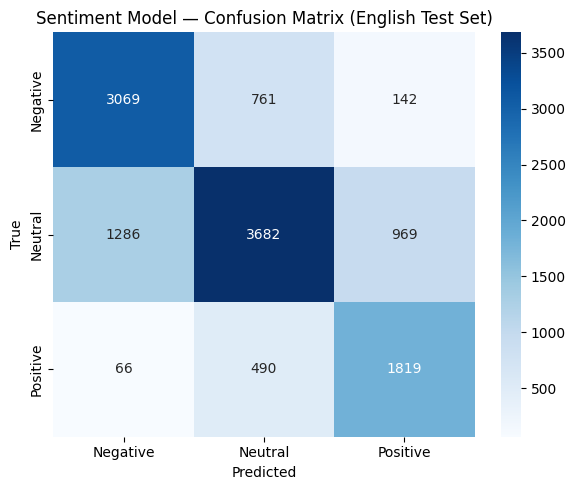

In [17]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

predictions = trainer.predict(tokenized["test"])
pred_labels = np.argmax(predictions.predictions, axis=1)
true_labels = tokenized["test"]["label"]

cm = confusion_matrix(true_labels, pred_labels)
labels = ["Negative", "Neutral", "Positive"]

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Sentiment Model — Confusion Matrix (English Test Set)")
plt.tight_layout()
plt.savefig("/kaggle/working/sentiment_confusion_matrix.png", dpi=150)
plt.show()